# Task 3 : cGan Implementation

In [30]:
import torch
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import copy
import json
from datetime import datetime
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms
from torchinfo import summary
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim



In [31]:
# Reproducibility
SEED = 42                             #to make the random operations more stable between runs
random.seed(SEED)
np.random.seed(SEED)                  #fixes randomness from numpy
torch.manual_seed(SEED)               #fixes randomness from pytorch

#if gpu exists it also fixes gpu randomness
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#chooses whether to use GPU or CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#prints whether GPU or CPU is used
print("Using device:", device)

#if GPU is available prints its name
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

#directory where all experiment folders will be saved
SAVE_ROOT = os.path.expanduser("~/Bureau/cgan_experiments")

#create the directory if it does not already exist
os.makedirs(SAVE_ROOT, exist_ok=True)

print("Experiments will be saved in:", SAVE_ROOT)


Using device: cuda
GPU: NVIDIA GeForce RTX 3060
Experiments will be saved in: /home/lina/Bureau/cgan_experiments


In [32]:
#helper function used to convert resize ratio into a valid image size
#the result is rounded up to the nearest multiple of 16 because the model downsamples several times
#example: if image_size_original = 256 and ratio = 0.2, raw size = 51.2 and final size = 64
def ratio_to_valid_size(image_size_original, ratio, base=16):
    raw_size = image_size_original * ratio                    #computes target image size before rounding
    valid_size = math.ceil(raw_size / base) * base            #rounds up to nearest multiple of base
    return int(valid_size)                                    #returns final integer image size


## 1. Load and preprocess dataset

In [33]:
# Hyperparameters
image_size_original = 256   #original reference size used to calculate resize values
image_size_ratio = 0.25     #resize ratio | example: 0.25 gives 64 if image_size_original = 256
image_size = ratio_to_valid_size(image_size_original, image_size_ratio) #final resize value used by the dataset, rounded to a valid size
channels = 1      #PET and mask are grayscale so each has one channel
batch_size = 4    #the model trains on 4 samples at a time
n_epochs = 100
lr = 0.0002

#first momentum coefficient for Adam optimizer -> controls how much the optimizer remembers past updates
beta1 = 0.5

sample_every = 5  #every 5 epochs, generated images are shown

#weight of the L1 reconstruction loss -> makes the generator care about pixel-level similarity between generated PET and real PET
lambda_l1 = 200

#min number of samples required
min_dataset_len = 100

#dataset paths
data_root = os.path.expanduser("~/Téléchargements/autopet")
image_dir = os.path.join(data_root, "imagesTr")
mask_dir = os.path.join(data_root, "labelsTr")

#creagting a custom dataset class
class AutoPETSliceDataset(Dataset):

    #function runs when the dataset is created, It receives: image folder, mask folder, image size, minimum tumor pixels per slice
    def __init__(self, image_dir, mask_dir, image_size=64, min_mask_pixels=100, resize_images=True, show_resize_debug=False):
        #stores those values inside the dataset object
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.min_mask_pixels = min_mask_pixels
        self.resize_images = resize_images          #if True PET and mask are resized, if False original slice size is kept
        self.show_resize_debug = show_resize_debug  #if True shows PET and mask before/after resizing for the first sample

        #creating PET and mask resizing
        self.resize_pet = transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_mask = transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.NEAREST)
        #PET is resized with bilinear interpolation because PET is continuous intensity data
        #mask is resized with nearest-neighbor interpolation to keep binary values

        image_files = sorted([f for f in os.listdir(image_dir) if f.endswith(".nii.gz")]) #gets all image files ending in .nii.gz
        mask_files = sorted([f for f in os.listdir(mask_dir) if f.endswith(".nii.gz")])   #gets all mask files ending with .nii.gz

        print(f"Total image files: {len(image_files)}")
        print(f"Total mask files: {len(mask_files)}")

        mask_map = {f.replace(".nii.gz", ""): f for f in mask_files}                      #case_name -> mask_file | example patient001 -> patient001.nii.gz

        cases = {}                                              #creates an empty dictionary to group CT and PET files by case
        for img_file in image_files:                            #loops through all image files
            base = img_file.replace(".nii.gz", "")              #removes file extension
            if base.endswith("_0000"):                          #checks if file is CT
                case_id = base[:-5]                             #removes _0000 from filename to get case ID
                cases.setdefault(case_id, {})["ct"] = img_file  #stores CT file under that case
            elif base.endswith("_0001"):                        #checks is file is PET
                case_id = base[:-5]                             #gets case ID
                cases.setdefault(case_id, {})["pet"] = img_file #stores PET file under that case

        self.samples = []   #creates an empty list, each item will later contain: PET path, mask path, slice index

        total_slices_before_filtering = 0

        for case_id, mods in cases.items(): #loops through each case

            if "pet" in mods and case_id in mask_map: #keeps only cases that have PET image and mask

                # print(f"[CASE] {case_id} | PET: {mods.get('pet')} | MASK: {mask_map.get(case_id)}")  #prints which case is being used (( only for debugging ))

                pet_path = os.path.join(self.image_dir, mods["pet"])        #creates full PET file path
                mask_path = os.path.join(self.mask_dir, mask_map[case_id])  #creates full mask file path

                mask_vol = nib.load(mask_path).get_fdata() #loads the 3D mask volume
                total_slices_before_filtering += mask_vol.shape[2]
                mask_sums = mask_vol.sum(axis=(0, 1))      #for each slice counts how many tumor pixels exist, result is one value per slice
                valid_slices = np.where(mask_sums > self.min_mask_pixels)[0] #ignore slices with no tumor or tiny tumor

                # print(f"[SLICES] {case_id} | Total: {mask_vol.shape[2]} | Valid: {len(valid_slices)}") #check total slices and usable slices (( debuggig only ))

                for z in valid_slices:
                    #if len(self.samples) < 10:
                    #    print(f"[ADD] z={z} | pet={os.path.basename(pet_path)} | mask={os.path.basename(mask_path)}")  #(( debuging only ))

                    self.samples.append((pet_path, mask_path, int(z))) #adds one usable sample, each sample means: one 2D PET slice + matching 2D mask slice

        print(f"Initial dataset size (number of slices before filtering): {total_slices_before_filtering}")
        print(f"Final dataset size (number of valid slices): {len(self.samples)}")

    def __len__(self):      #returns dataset length | used by DataLoader
        return len(self.samples)

    def __getitem__(self, idx):   #loads one sample | is called automatically by train_loader, val_loader
        pet_path, mask_path, z = self.samples[idx]  #gets PET path, mask path, slice number

        pet_vol = nib.load(pet_path).get_fdata()          #loads full 3D PET volume
        mask_vol = nib.load(mask_path).get_fdata()        #loads full 3D mask volume

        pet = pet_vol[:, :, z].astype(np.float32)         #extracts one 2D PET slice
        mask = (mask_vol[:, :, z] > 0).astype(np.float32) #extracts matching mask slice and binirizes it, values become: 0 = background | 1 = tumor

        pet = (pet - pet.min()) / (pet.max() - pet.min() + 1e-8) #normalizes PET to [0,1] | (value - min) / (max - min)
        #detailed about normalization in text below

        pet = torch.tensor(pet).unsqueeze(0)      #converts PET from NumPy to PyTorch tensor, unsqueeze(0) adds channel dimension,shape changes: [H, W] -> [1, H, W]
        mask = torch.tensor(mask).unsqueeze(0)    #same for mask

# check resizing logic: visualize before resizing
        if self.show_resize_debug and idx == 0:  # only visualize first sample to avoid flooding

            pet_before = pet.squeeze(0).cpu().numpy()
            mask_before = mask.squeeze(0).cpu().numpy()

            plt.figure(figsize=(6, 3))
            plt.subplot(1, 2, 1)
            plt.title("PET before resize")
            plt.imshow(pet_before, cmap="gray")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.title("Mask before resize")
            plt.imshow(mask_before, cmap="gray")
            plt.axis("off")

            plt.show()

#resizing PET and mask to the selected image_size
        if self.resize_images:
            pet = self.resize_pet(pet)
            mask = self.resize_mask(mask) #nearest-neighbor keeps mask binary

# check resizing logic: visualize after resizing
        if self.show_resize_debug and idx == 0:
            pet_after = pet.squeeze(0).cpu().numpy()
            mask_after = mask.squeeze(0).cpu().numpy()

            plt.figure(figsize=(6, 3))
            plt.subplot(1, 2, 1)
            plt.title("PET after resize" if self.resize_images else "PET without resize")
            plt.imshow(pet_after, cmap="gray")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.title("Mask after resize" if self.resize_images else "Mask without resize")
            plt.imshow(mask_after, cmap="gray")
            plt.axis("off")

            plt.show()

# convert PET from [0,1] to [-1,1] to match Tanh output of generator because the generator uses Tanh at the output which produces values in [-1,1], so the target must be in the same range
        pet = pet * 2.0 - 1.0

#returns input condition = mask, target output = PET |used later in training: ((for real_masks, real_pet in train_loader))
        return mask, pet


We normalize the PET image to make training stable by bringing values between 0 and 1. (makes training easier, keeps values in a stable range)
It is done by subtracting the minimum and dividing by the range.
However, since this is done per slice, we lose the real intensity information.
So the model learns the structure well, but not the true intensity values.

In [34]:
def check_batch_shapes(loader): #checks one batch from a DataLoader and visualizes masks/PET images
    masks, pet_images = next(iter(loader)) #takes one batch from training data | this calls __getitem__
    print("Mask batch shape:", masks.shape)       #expected [batch_size, 1, image_size, image_size] if resizing is used
    print("PET batch shape:", pet_images.shape)   #expected [batch_size, 1, image_size, image_size] if resizing is used
    print("Mask value range:", masks.min().item(), "to", masks.max().item())  #expected 0 to 1
    print("PET value range:", pet_images.min().item(), "to", pet_images.max().item()) #expected values inside -1 to 1

    plt.figure(figsize=(8, 3 * min(4, masks.size(0))))

    for i in range(min(4, masks.size(0))):
        plt.subplot(min(4, masks.size(0)), 2, 2 * i + 1)
        plt.imshow(masks[i][0].cpu(), cmap="gray")
        plt.title("Mask")
        plt.axis("off")

        plt.subplot(min(4, masks.size(0)), 2, 2 * i + 2)
        pet_for_display = (pet_images[i][0].cpu() + 1.0) / 2.0 #brings PET back from [-1,1] to [0,1] only for visualization
        plt.imshow(pet_for_display, cmap="gray")
        plt.title("PET")
        plt.axis("off")

    plt.tight_layout()
    plt.show()



## 2. Conditional discriminator

In [35]:
class Discriminator(nn.Module): #decides whether a PET image is real or fake given the mask
    def __init__(self):
        super().__init__()
        # mask is given as input because this is a conditional GAN
        # the discriminator checks if the PET image is realistic and matches the mask

        self.model = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=4, stride=2, padding=1),   #input has 2 channels:mask + PET | 64×64 -> 32×32
            nn.LeakyReLU(0.2, inplace=True), #to keep small negative values instead of killing them completely

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), #second convolution, size: 32×32 -> 16×16 | channels: 64 -> 128
            nn.BatchNorm2d(128), #stabilized activations
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), #third convolution, size: 16×16 -> 8×8 | channels: 128 -> 256
            nn.BatchNorm2d(256), #normalization
            nn.LeakyReLU(0.2, inplace=True),#activaton

            nn.Conv2d(256, 1, kernel_size=4, stride=1, padding=1), #final prediction layer, outputs one-channel map
            nn.Sigmoid() #Converts output to values between 0 and 1, meaning close to 1 = real | close to 0 = fake
        )

    def forward(self, masks, pet_images): #how data passes through discriminator
        x = torch.cat([masks, pet_images], dim=1) #combines mask and PET along channel dimension (example in text below)
        return self.model(x)

## 3. Conditional generator

In [36]:
class Generator(nn.Module): #creates a PET image from a mask
    def __init__(self):
        super().__init__()
        #the mask already provides full spatial information, so the generator does not need noise to create structure. The task becomes learning a direct mapping from mask to PET, rather than generating images from randomness.

        #encoder

        self.encoder = nn.Sequential( #compresses the mask into features
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),   #1×64×64 -> 64×32×32
            nn.LeakyReLU(0.2, inplace=True),    #used in encoder to avoid losing information completely when values are negative

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), #64×32×32 -> 128×16×16
            nn.BatchNorm2d(128), #stabilizes layer outputs
            nn.LeakyReLU(0.2, inplace=True), #activation

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), #128×16×16 → 256×8×8 | this is the encoded feature map
            nn.BatchNorm2d(256), #normalization
            nn.LeakyReLU(0.2, inplace=True)#activation
        )


        #decoder

        self.decoder = nn.Sequential(    #reconstructs PET from compressed features
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  #upsamples: 8×8 -> 16×16 | this replaced ConvTranspose2d to reduce checkerboard artifacts(systematic noise in the generated images)
            nn.Conv2d(256, 128, kernel_size=3, stride=1, padding=1),            #processes the upsampled feature map | channels: 256 -> 128 | size stays: 16×16
            nn.BatchNorm2d(128),    #normalization
            nn.ReLU(inplace=True),  #helps reconstruct clean positive features

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  #16×16 -> 32×32
            nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1),             #128 -> 64
            nn.BatchNorm2d(64),     #normalization
            nn.ReLU(inplace=True),  #activation

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False), #32×32 -> 64×64
            nn.Conv2d(64, 1, kernel_size=3, stride=1, padding=1),  #creates final one-channel PET image
            nn.Tanh() #forces output range to: [-1,1] this matches the PET target after: pet = pet * 2.0 - 1.0
        )

    def forward(self, masks):   #defines generator input
        x = self.encoder(masks) #compresses masks
        x = self.decoder(x)     #reconstructs PET
        return x                #returns generated PET

## 4. Initialize models and optimizers

In [37]:
def print_model_summaries(image_size, device): #prints generator and discriminator summaries for the selected image_size
    G_summary = Generator().to(device)      #creates temporary generator only for summary
    D_summary = Discriminator().to(device)  #creates temporary discriminator only for summary

    # Generator summary
    summary(G_summary, input_size=(1, 1, image_size, image_size))

    print("\n" + "="*50 + "\n")

    # Discriminator summary
    summary(D_summary, input_size=[(1, 1, image_size, image_size), (1, 1, image_size, image_size)])



## 5. Helper functions

In [38]:
@torch.no_grad() #no gradients are calculated, used because this is visualization, not training
def summarize_performance(generator, loader, epoch, n_samples=4, device=device): #show mask, real PET, and generated PET
    generator.eval() #sets generator to evaluation mode

    real_masks, real_pet = next(iter(loader)) #takes one batch from loader
    real_masks = real_masks.to(device)        #moves masks to GPU/CPU
    fake_pet = generator(real_masks).cpu()    #generates fake PET and moves it to CPU for plotting

    # real_pet is in [-1,1], bring back to [0,1] for vizualization
    real_pet = ((real_pet.cpu() + 1.0) / 2.0)
    fake_pet = ((fake_pet + 1.0) / 2.0)

    #then plotting shows mask | real PET | fake PET

    plt.figure(figsize=(9, 3 * n_samples))

    for i in range(min(n_samples, real_masks.size(0))):
        plt.subplot(n_samples, 3, 3 * i + 1)
        plt.imshow(real_masks[i][0].cpu(), cmap="gray")
        plt.title("Mask")
        plt.axis("off")

        plt.subplot(n_samples, 3, 3 * i + 2)
        plt.imshow(real_pet[i][0], cmap="gray")
        plt.title("Real PET")
        plt.axis("off")

        plt.subplot(n_samples, 3, 3 * i + 3)
        plt.imshow(fake_pet[i][0], cmap="gray")
        plt.title("Fake PET")
        plt.axis("off")

    plt.suptitle(f"Generated PET from masks at epoch {epoch}")
    plt.tight_layout()
    plt.show()

@torch.no_grad()
def evaluate_generator(generator, loader, device, split_name="data"): #compute PSNR and SSIM on selected data | defines evaluation function
    generator.eval() #evaluation mode

    #lists to store metrics for each image
    psnr_values = []
    ssim_values = []

    for masks, real_pet in loader: #loops over batches
        #moves data to GPU/CPU
        masks = masks.to(device)
        real_pet = real_pet.to(device)

        #generates PET
        fake_pet = generator(masks)

        # convert from [-1,1] to [0,1] before computing image similarity metrics
        real_pet = (real_pet + 1.0) / 2.0
        fake_pet = (fake_pet + 1.0) / 2.0

        #converts tensors to NumPy arrays.
        real_pet = real_pet.cpu().numpy()
        fake_pet = fake_pet.cpu().numpy()

        for i in range(real_pet.shape[0]): #loops through images in the batch
            #gets one 2D image
            real_img = real_pet[i, 0]
            fake_img = fake_pet[i, 0]

            psnr_values.append(psnr(real_img, fake_img, data_range=1.0)) #computes PSNR | higher = better.
            ssim_values.append(ssim(real_img, fake_img, data_range=1.0)) #computes SSIM | closer to 1 = better

    #averages all results
    mean_psnr = np.mean(psnr_values)
    mean_ssim = np.mean(ssim_values)

    print(f"Mean PSNR on {split_name}: {mean_psnr:.4f}")
    print(f"Mean SSIM on {split_name}: {mean_ssim:.4f}")

    return mean_psnr, mean_ssim



def save_model(generator, discriminator, params, history, metrics, experiment_name="experiment", save_root=SAVE_ROOT): #saves the trained model and experiment information in a new timestamped folder
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S") #creates visible timestamp for folder name
    save_dir = os.path.join(save_root, f"{experiment_name}_{timestamp}") #creates folder name using experiment name and timestamp
    os.makedirs(save_dir, exist_ok=True) #creates the folder if it does not already exist

    generator_path = os.path.join(save_dir, "generator_best.pth") #path where generator weights will be saved
    discriminator_path = os.path.join(save_dir, "discriminator_best.pth") #path where discriminator weights will be saved
    params_json_path = os.path.join(save_dir, "parameters.json") #path where parameters will be saved as json
    params_csv_path = os.path.join(save_dir, "parameters.csv") #path where parameters will be saved as csv
    metrics_json_path = os.path.join(save_dir, "metrics.json") #path where metrics will be saved as json
    history_json_path = os.path.join(save_dir, "history.json") #path where training history will be saved as json

    torch.save(generator.state_dict(), generator_path) #saves generator weights, this is the model used later for PET generation
    torch.save(discriminator.state_dict(), discriminator_path) #saves discriminator weights for completeness

    params_to_save = {k: str(v) if k == "device" else v for k, v in params.items()} #converts device to string so it can be saved in json/csv
    metrics_to_save = {k: float(v) for k, v in metrics.items()} #converts metric values to regular floats for saving

    with open(params_json_path, "w") as f: #opens json file for parameters
        json.dump(params_to_save, f, indent=4) #saves parameters in readable json format

    pd.DataFrame([params_to_save]).to_csv(params_csv_path, index=False) #saves parameters as one-row csv file

    with open(metrics_json_path, "w") as f: #opens json file for metrics
        json.dump(metrics_to_save, f, indent=4) #saves PSNR/SSIM values in readable json format

    with open(history_json_path, "w") as f: #opens json file for training history
        json.dump(history, f, indent=4) #saves training and validation losses

    print(f"Model and experiment files saved in: {save_dir}") #prints folder location
    return save_dir, generator_path #returns folder path and generator model path


def save_metrics(metrics, save_dir): #updates the metrics files after the saved best model is loaded and evaluated
    metrics_json_path = os.path.join(save_dir, "metrics.json") #path where metrics will be saved as json
    metrics_csv_path = os.path.join(save_dir, "metrics.csv") #path where metrics will be saved as csv
    metrics_to_save = {k: float(v) for k, v in metrics.items()} #converts metric values to regular floats for saving

    with open(metrics_json_path, "w") as f: #opens json file for metrics
        json.dump(metrics_to_save, f, indent=4) #saves train/validation/test PSNR and SSIM values

    pd.DataFrame([metrics_to_save]).to_csv(metrics_csv_path, index=False) #saves metrics as one-row csv file

    print(f"Updated metrics saved in: {save_dir}") #prints folder location

def load_generator_model(model_path, device): #loads saved generator weights into a new generator model
    loaded_generator = Generator().to(device) #creates a new generator with the same architecture
    loaded_generator.load_state_dict(torch.load(model_path, map_location=device)) #loads saved best generator weights
    loaded_generator.eval() #sets loaded generator to evaluation mode
    return loaded_generator #returns loaded generator


## 6. Training loop
### Purpose

This is the main training function.

It trains:

* discriminator
* generator
* validation
* early stopping

In [39]:
def train_cgan(
    generator,
    discriminator,
    train_loader,
    val_loader,
    optimizer_G,
    optimizer_D,
    criterion_adv,
    criterion_l1,
    lambda_l1,
    device,
    n_epochs,
    patience=15,
    warmup=10,
    min_delta=1e-6,
    sample_every=5,
    visualize_during_training=False
): #defines training function, inputs:generator | discriminator |training data | validation data | optimizers | losses | number of epochs | early stopping parameters

    #stores losses per epoch, used later for plotting
    history = {
        "d_loss": [], "g_loss": [],
        "d_val": [], "g_val": []
    }

#labels for discriminator, real = 0.9 instead of 1.0 to avoid overconfidence.
#intermediate values like 0.5 would make the real/fake distinction unclear.
#fake = 0

    real_label_value = 0.9
    fake_label_value = 0.0

    best_score = float("inf") #best validation generator loss so far, starts as infinity because lower is better.
    #will store best generator/discriminator weights
    best_g_weights = None
    best_d_weights = None
    wait = 0                  #counts epochs without improvement after warmup

    for epoch in range(n_epochs): #main epoch loop
        #stores batch losses for current epoch
        d_epoch_losses = []
        g_epoch_losses = []

        #training mode
        generator.train()
        discriminator.train()

        #batch loop
        for real_masks, real_pet in train_loader: #gets batches from DataLoader

            #moves tensors to GPU/CPU
            real_masks = real_masks.to(device, non_blocking=True)
            real_pet = real_pet.to(device, non_blocking=True)
            #non_blocking = True means the program does not wait unnecessarily while copying data from CPU to GPU

            # Train D
            optimizer_D.zero_grad() #clears old discriminator gradients
            #returns out_real -> prediced value from real pet img
            out_real = discriminator(real_masks, real_pet) #discriminator sees real pair: mask + real PET, outputs prediction
            real_labels = torch.full_like(out_real, real_label_value, device=device) #creates label tensor same shape as prediction, filled with 0.9

            d_real_loss = criterion_adv(out_real, real_labels) #measures how well discriminator recognizes real PET as real

            fake_pet = generator(real_masks)  #generator creates fake PET from mask
            out_fake = discriminator(real_masks, fake_pet.detach()) #returns out_fake: prediced value from fake pet img | .detach() means do not update generator in discriminator step
            fake_labels = torch.full_like(out_fake, fake_label_value, device=device) #creates fake labels filled with 0
            d_fake_loss = criterion_adv(out_fake, fake_labels) #measures how well discriminator recognizes fake PET as fake

            #average of real and fake loss
            #we average the real and fake losses so the discriminator learns both tasks equally and the loss doesn’t become unnecessarily large
            d_loss = 0.5 * (d_real_loss + d_fake_loss)

            d_loss.backward() #calculates discriminator gradients
            optimizer_D.step()#updates discriminator weight

            # Train G
            optimizer_G.zero_grad()                               #clears old generator gradients
            fake_pet = generator(real_masks)                      #generates fake PET again
            out_fake = discriminator(real_masks, fake_pet)        #discriminator evaluates fake PET | no .detach() here because generator must learn
            real_labels_g = torch.full_like(out_fake, real_label_value, device=device) #generator wants fake PET to be classified as real => target label = 0.9
            adv_loss = criterion_adv(out_fake, real_labels_g)     #adversarial loss, it tells generator to make fake PET look real
            l1_loss = criterion_l1(fake_pet, real_pet)            #compares fake PET and real PET pixel by pixel, it tells generator to stay close to the correct PET.
            g_loss = adv_loss + lambda_l1 * l1_loss               #final generator loss. 2 parts: adv_loss -> realism, L1 loss -> similarity to real PET

#debug print block : runs only for the first batch of first epoch, prints shapes and loss values to understand the generator step
            if epoch == 0 and len(g_epoch_losses) == 0:
                print("G step: old gradients cleared")
                print("Generated PET shape:", fake_pet.shape)
                print("Discriminator output shape:", out_fake.shape)
                print("Discriminator output mean:", out_fake.mean().item())
                print("Generator target label:", real_label_value)
                print("Adversarial loss:", adv_loss.item())
                print("L1 loss:", l1_loss.item())
                print("Total generator loss:", g_loss.item())

            g_loss.backward()  #calculates generator gradients
            optimizer_G.step() #updates generator weights

            #stores batch losses | .item() converts tensor to normal number
            d_epoch_losses.append(d_loss.item())
            g_epoch_losses.append(g_loss.item())

        #end of epoch
        #stores average training losses for the epoch
        history["d_loss"].append(np.mean(d_epoch_losses))
        history["g_loss"].append(np.mean(g_epoch_losses))

        # validation
        #evaluation mode
        generator.eval()
        discriminator.eval()

        d_val_losses, g_val_losses = [], []  #stores validation losses

        with torch.no_grad(): #no gradients during validation
            #validation loop repeats the same loss calculations, but does not update weights
            for real_masks, real_pet in val_loader:
                real_masks = real_masks.to(device, non_blocking=True)
                real_pet = real_pet.to(device, non_blocking=True)

                out_real = discriminator(real_masks, real_pet)
                real_labels = torch.full_like(out_real, real_label_value, device=device)
                d_real_loss = criterion_adv(out_real, real_labels)

                fake_pet = generator(real_masks)
                out_fake = discriminator(real_masks, fake_pet)
                fake_labels = torch.full_like(out_fake, fake_label_value, device=device)
                d_fake_loss = criterion_adv(out_fake, fake_labels)

                d_val = 0.5 * (d_real_loss + d_fake_loss)

                real_labels_g = torch.full_like(out_fake, real_label_value, device=device)
                g_val = criterion_adv(out_fake, real_labels_g) + lambda_l1 * criterion_l1(fake_pet, real_pet)

                d_val_losses.append(d_val.item())
                g_val_losses.append(g_val.item())

        #stores validation losses
        history["d_val"].append(np.mean(d_val_losses))
        history["g_val"].append(np.mean(g_val_losses))

        val_score = history["g_val"][-1] #takes latest generator validation loss | used for early stopping
        #list where we store generator validation loss for each epoch, [-1] = last element, so val_score = history["g_val"][-1] means take the latest generator validation loss

        print(
            f"Epoch [{epoch+1}/{n_epochs}] | "
            f"D: {history['d_loss'][-1]:.4f} | G: {history['g_loss'][-1]:.4f} | "
            f"D_val: {history['d_val'][-1]:.4f} | G_val: {history['g_val'][-1]:.4f}"
        )   #prints epoch losses

        if val_score < best_score - min_delta: #checks if validation generator loss improved enough
            best_score = val_score   #updates best score

            #saves best weights
            best_g_weights = copy.deepcopy(generator.state_dict())
            best_d_weights = copy.deepcopy(discriminator.state_dict())

            #resets patience counter
            wait = 0

        elif epoch + 1 > warmup:  #if no improvement and warmup is finished, increase wait
            wait += 1

        #checks if still inside warmup
        if epoch < warmup:
            print(f"[Epoch {epoch+1}] WARMUP ({epoch+1}/{warmup})") #prints warmup status
        else:   #after warmup
            if wait == 0: #means improvement happened
                print(f"[Epoch {epoch+1}] PATIENCE | improvement detected -> reset wait") #prints that patience reset
            else:
                print(f"[Epoch {epoch+1}] PATIENCE | wait = {wait}/{patience}")    #prints patience counter

        if visualize_during_training and ((epoch + 1) % sample_every == 0): #every selected number of epochs if visualization is enabled
            summarize_performance(generator, val_loader, epoch + 1, device=device) #shows generated images on validation data

        if wait >= patience: #if no improvement for too many epochs
            print(f"Early stopping at epoch {epoch+1}. Restoring best weights.") #prints early stopping message

            #restores best model weights
            if best_g_weights is not None:
                generator.load_state_dict(best_g_weights)
            if best_d_weights is not None:
                discriminator.load_state_dict(best_d_weights)

            #stops training
            break

    #after training checks if best weights exist
    if best_g_weights is not None:
        #restores best weights even if early stopping did not trigger
        generator.load_state_dict(best_g_weights)
        discriminator.load_state_dict(best_d_weights)
        print("Best weights restored.")

    #returns losses
    return history



## 7. Parameterized experiment function


In [40]:
def run_experiment(
    image_dir,
    mask_dir,
    image_size_original=256,
    image_size_ratio=0.25,
    image_size=None,
    resize_base=16,
    min_mask_pixels=100,
    batch_size=4,
    n_epochs=80,
    lr=0.0002,
    beta1=0.5,
    lambda_l1=200,
    patience=15,
    warmup=10,
    min_delta=1e-6,
    sample_every=5,
    val_ratio=0.2,
    test_ratio=0.1,
    num_workers=2,
    pin_memory=True,
    seed=42,
    min_dataset_len=100,
    device=device,
    resize_images=True,
    show_resize_debug=False,
    visualize_during_training=False,
    visualize_at_end=True,
    print_summary=False,
    experiment_name="experiment",
    save_root=SAVE_ROOT
): #main experiment function, creates dataset/loaders/models/losses/optimizers, trains model, saves model, loads saved best model, evaluates model and returns results

    if image_size is None:
        image_size = ratio_to_valid_size(image_size_original, image_size_ratio, base=resize_base) #calculates resize value from ratio and rounds it to a valid size

    print("=" * 70)
    print("Starting experiment")
    print(f"experiment_name={experiment_name}")
    print(f"image_size_original={image_size_original}, image_size_ratio={image_size_ratio}, image_size={image_size}")
    print(f"min_mask_pixels={min_mask_pixels}, batch_size={batch_size}, n_epochs={n_epochs}")
    print(f"lr={lr}, beta1={beta1}, lambda_l1={lambda_l1}, patience={patience}, warmup={warmup}")
    print("=" * 70)

    full_dataset = AutoPETSliceDataset( #creates full dataset. this calls __init__()
        image_dir=image_dir,
        mask_dir=mask_dir,
        image_size=image_size,
        min_mask_pixels=min_mask_pixels,
        resize_images=resize_images,
        show_resize_debug=show_resize_debug
    )

    #stop if dataset is too small
    if len(full_dataset) < min_dataset_len:
        raise ValueError(f"Dataset too small: {len(full_dataset)} samples found")

    val_size = int(val_ratio * len(full_dataset))    #validation size = selected validation ratio of dataset
    test_size = int(test_ratio * len(full_dataset))  #test size = selected test ratio of dataset
    train_size = len(full_dataset) - val_size - test_size #training size = remaining part of dataset

    rest_dataset, test_dataset = random_split( #first split keeps the test set separate
        full_dataset,
        [train_size + val_size, test_size],
        generator=torch.Generator().manual_seed(seed)
    )

    train_dataset, val_dataset = random_split( #second split separates training and validation
        rest_dataset,
        [train_size, val_size],
        generator=torch.Generator().manual_seed(seed)
    )

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=pin_memory)   #creates training loader | shuffle=True -> training data is shuffled | num_workers uses CPU workers to load data, it does not mean GPUs | pin_memory=True -> helps faster transfer to GPU.
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)      #creates validation loader | shuffle=False -> validation data is not shuffled
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)    #creates test loader | shuffle=False -> test data is not shuffled

    print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")
    print(f"Train batches per epoch: {len(train_loader)}")
    print(f"Validation batches: {len(val_loader)}")
    print(f"Test batches: {len(test_loader)}")

    if show_resize_debug:
        _ = full_dataset[0] #forces __getitem__ to run and shows before/after resizing plots

    G = Generator().to(device)      #creates generator and sends it to GPU/CPU
    D = Discriminator().to(device)  #creates discriminator and sends it to GPU/CPU

    criterion_adv = nn.BCELoss()  #binary cross-entropy | used for real/fake classification
    criterion_l1 = nn.L1Loss()    #L1 loss | measures: average absolute difference | used to compare generated PET and real PET
                                  #L1 = average of |prediction - target| ->  ensures generated image stays close to the ground truth

    #Beta1 controls how much past gradients influence the current update
    #The same lr is used for both networks to keep training balanced, since if one learns faster than the other, the training becomes unstable
    optimizer_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999)) #optimizer for generator, updates generator weights
    optimizer_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999)) #optimizer for discriminator, updates discriminator weights

    if print_summary:
        print_model_summaries(image_size=image_size, device=device) #prints model summaries for the selected image_size

    history = train_cgan( #trains the cGAN using the selected experiment parameters
        generator=G,
        discriminator=D,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer_G=optimizer_G,
        optimizer_D=optimizer_D,
        criterion_adv=criterion_adv,
        criterion_l1=criterion_l1,
        lambda_l1=lambda_l1,
        device=device,
        n_epochs=n_epochs,
        patience=patience,
        warmup=warmup,
        min_delta=min_delta,
        sample_every=sample_every,
        visualize_during_training=visualize_during_training
    )

    params = { #stores all experiment parameters, this will also be saved with the model
        "experiment_name": experiment_name,
        "image_size_original": image_size_original,
        "image_size_ratio": image_size_ratio,
        "image_size": image_size,
        "resize_base": resize_base,
        "min_mask_pixels": min_mask_pixels,
        "batch_size": batch_size,
        "n_epochs": n_epochs,
        "lr": lr,
        "beta1": beta1,
        "lambda_l1": lambda_l1,
        "patience": patience,
        "warmup": warmup,
        "min_delta": min_delta,
        "sample_every": sample_every,
        "val_ratio": val_ratio,
        "test_ratio": test_ratio,
        "num_workers": num_workers,
        "pin_memory": pin_memory,
        "seed": seed,
        "resize_images": resize_images,
        "device": str(device)
    }

    metrics = {} #metrics are created empty before saving, then updated after the saved best model is loaded and evaluated

    save_dir, generator_path = save_model( #saves best generator/discriminator and experiment information in a timestamped folder
        generator=G,
        discriminator=D,
        params=params,
        history=history,
        metrics=metrics,
        experiment_name=experiment_name,
        save_root=save_root
    )

    loaded_G = load_generator_model(generator_path, device) #loads the saved best generator from disk

    if visualize_at_end:
        print("Train visualization with loaded best model:")
        summarize_performance(loaded_G, train_loader, epoch="best train", n_samples=6, device=device)

        print("Validation visualization with loaded best model:")
        summarize_performance(loaded_G, val_loader, epoch="best validation", n_samples=6, device=device)

        print("Test visualization with loaded best model:")
        summarize_performance(loaded_G, test_loader, epoch="best test", n_samples=6, device=device)

    #after saving and loading, the best model is evaluated on train, validation and test
    print("Train quantitative evaluation with loaded best model:")
    train_psnr, train_ssim = evaluate_generator(loaded_G, train_loader, device, split_name="train data")

    print("Validation quantitative evaluation with loaded best model:")
    loaded_val_psnr, loaded_val_ssim = evaluate_generator(loaded_G, val_loader, device, split_name="validation data")

    print("Test quantitative evaluation with loaded best model:")
    loaded_test_psnr, loaded_test_ssim = evaluate_generator(loaded_G, test_loader, device, split_name="test data")

    metrics = { #stores train, validation and test metrics after loading the saved best model
        "train_psnr": train_psnr,
        "train_ssim": train_ssim,
        "val_psnr": loaded_val_psnr,
        "val_ssim": loaded_val_ssim,
        "test_psnr": loaded_test_psnr,
        "test_ssim": loaded_test_ssim
    }

    save_metrics(metrics, save_dir) #updates metrics.json and creates metrics.csv inside the same experiment folder

    results = { #stores all outputs that may be needed later for plots and comparison
        "params": params,
        "history": history,
        "val_psnr": loaded_val_psnr,
        "val_ssim": loaded_val_ssim,
        "test_psnr": loaded_test_psnr,
        "test_ssim": loaded_test_ssim,
        "train_psnr": train_psnr,
        "train_ssim": train_ssim,
        "generator": loaded_G,
        "discriminator": D,
        "train_loader": train_loader,
        "val_loader": val_loader,
        "test_loader": test_loader,
        "train_dataset": train_dataset,
        "val_dataset": val_dataset,
        "test_dataset": test_dataset,
        "save_dir": save_dir,
        "generator_path": generator_path
    }

    return results


## 8. Single experiment


In [41]:
"""#single experiment example
#uncomment the block below if you want to run only one experiment

exp1 = run_experiment(
     image_dir=image_dir,
     mask_dir=mask_dir,
     image_size_original=image_size_original,
     image_size_ratio=0.25,
     image_size=None,
     min_mask_pixels=100,
     batch_size=batch_size,
     n_epochs=10,
     lr=lr,
     beta1=beta1,
     lambda_l1=lambda_l1,
     patience=4,
     warmup=3,
     min_delta=1e-6,
     sample_every=sample_every,
     val_ratio=0.2,
     test_ratio=0.1,
     num_workers=2,
     pin_memory=True,
     seed=SEED,
     min_dataset_len=min_dataset_len,
     device=device,
     resize_images=True,
     show_resize_debug=False,
     visualize_during_training=False,
     visualize_at_end=True,
     print_summary=False,
     experiment_name="single_test_experiment",
     save_root=SAVE_ROOT
)"""


'#single experiment example\n#uncomment the block below if you want to run only one experiment\n\nexp1 = run_experiment(\n     image_dir=image_dir,\n     mask_dir=mask_dir,\n     image_size_original=image_size_original,\n     image_size_ratio=0.25,\n     image_size=None,\n     min_mask_pixels=100,\n     batch_size=batch_size,\n     n_epochs=10,\n     lr=lr,\n     beta1=beta1,\n     lambda_l1=lambda_l1,\n     patience=4,\n     warmup=3,\n     min_delta=1e-6,\n     sample_every=sample_every,\n     val_ratio=0.2,\n     test_ratio=0.1,\n     num_workers=2,\n     pin_memory=True,\n     seed=SEED,\n     min_dataset_len=min_dataset_len,\n     device=device,\n     resize_images=True,\n     show_resize_debug=False,\n     visualize_during_training=False,\n     visualize_at_end=True,\n     print_summary=False,\n     experiment_name="single_test_experiment",\n     save_root=SAVE_ROOT\n)'

## 9. Plot training losses


In [42]:
"""#plots training/validation losses for exp1 if the optional single experiment was executed
if "exp1" in globals():
    history = exp1["history"] #gets losses from the selected experiment

    plt.figure(figsize=(8, 5))
    plt.plot(history['d_loss'], label='D train') #plots discriminator training loss
    plt.plot(history['g_loss'], label='G train') #plots generator training loss
    plt.plot(history['d_val'], label='D val')    #plots discriminator validation loss
    plt.plot(history['g_val'], label='G val')    #plots generator validation loss
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Losses')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("exp1 was not run. Run the optional single experiment first if you want this plot.")"""


'#plots training/validation losses for exp1 if the optional single experiment was executed\nif "exp1" in globals():\n    history = exp1["history"] #gets losses from the selected experiment\n\n    plt.figure(figsize=(8, 5))\n    plt.plot(history[\'d_loss\'], label=\'D train\') #plots discriminator training loss\n    plt.plot(history[\'g_loss\'], label=\'G train\') #plots generator training loss\n    plt.plot(history[\'d_val\'], label=\'D val\')    #plots discriminator validation loss\n    plt.plot(history[\'g_val\'], label=\'G val\')    #plots generator validation loss\n    plt.xlabel(\'Epoch\')\n    plt.ylabel(\'Loss\')\n    plt.title(\'Training and Validation Losses\')\n    plt.legend()\n    plt.grid(True)\n    plt.show()\nelse:\n    print("exp1 was not run. Run the optional single experiment first if you want this plot.")'

## 10. Combined resize ratio and min_mask_pixels experiments


In [43]:
#run several experiments using nested loops
#outer loop changes the resize value from 64 to 256
#inner loop changes min_mask_pixels from 10 to 200
#each experiment is trained, saved, loaded again, and evaluated on train/validation/test data

resize_sizes = [64, 128, 192, 256] #resize values tested in the experiment
min_mask_pixels_values = [10, 50, 100, 200] #mask filtering thresholds tested in the experiment

all_results = [] #stores results for all experiment combinations

for current_image_size in resize_sizes: #outer loop: changes resize value
    current_ratio = current_image_size / image_size_original #converts image_size to ratio for saving and tracking

    for min_pixels in min_mask_pixels_values: #inner loop: changes min_mask_pixels value
        experiment_name = f"resize_{current_image_size}_minpixels_{min_pixels}" #name used for saving this experiment

        print("=" * 70)
        print(f"Running experiment: image_size={current_image_size}, resize_ratio={current_ratio}, min_mask_pixels={min_pixels}")
        print("=" * 70)

        result = run_experiment(
            image_dir=image_dir,
            mask_dir=mask_dir,
            image_size_original=image_size_original,
            image_size_ratio=current_ratio,
            image_size=current_image_size,
            min_mask_pixels=min_pixels,
            batch_size=batch_size,
            n_epochs=50,
            lr=lr,
            beta1=beta1,
            lambda_l1=lambda_l1,
            patience=15,
            warmup=10,
            min_delta=1e-6,
            sample_every=sample_every,
            val_ratio=0.2,
            test_ratio=0.1,
            num_workers=2,
            pin_memory=True,
            seed=SEED,
            min_dataset_len=min_dataset_len,
            device=device,
            resize_images=True,
            show_resize_debug=False,
            visualize_during_training=False,
            visualize_at_end=False,
            print_summary=False,
            experiment_name=experiment_name,
            save_root=SAVE_ROOT
        )

        all_results.append(result) #adds current experiment output to the global result list

rows = []
for r in all_results: #creates one table row for each experiment
    rows.append({
        "experiment_name": r["params"]["experiment_name"],
        "image_size_ratio": r["params"]["image_size_ratio"],
        "image_size": r["params"]["image_size"],
        "min_mask_pixels": r["params"]["min_mask_pixels"],
        "train_psnr": r["train_psnr"],
        "train_ssim": r["train_ssim"],
        "val_psnr": r["val_psnr"],
        "val_ssim": r["val_ssim"],
        "test_psnr": r["test_psnr"],
        "test_ssim": r["test_ssim"],
        "best_g_val": min(r["history"]["g_val"]),
        "save_dir": r["save_dir"]
    })

results_df = pd.DataFrame(rows) #creates table with one row per experiment
results_df = results_df.sort_values(["image_size", "min_mask_pixels"]) #sorts results by resize value and min_mask_pixels
results_df


Running experiment: image_size=64, resize_ratio=0.25, min_mask_pixels=10
Starting experiment
experiment_name=resize_64_minpixels_10
image_size_original=256, image_size_ratio=0.25, image_size=64
min_mask_pixels=10, batch_size=4, n_epochs=50
lr=0.0002, beta1=0.5, lambda_l1=200, patience=15, warmup=10
Total image files: 66
Total mask files: 33
Initial dataset size (number of slices before filtering): 11185
Final dataset size (number of valid slices): 855
Train samples: 599, Val samples: 171, Test samples: 85
Train batches per epoch: 150
Validation batches: 43
Test batches: 22
G step: old gradients cleared
Generated PET shape: torch.Size([4, 1, 64, 64])
Discriminator output shape: torch.Size([4, 1, 7, 7])
Discriminator output mean: 0.4099391996860504
Generator target label: 0.9
Adversarial loss: 0.8802117705345154
L1 loss: 0.8933712840080261
Total generator loss: 179.55447387695312
Epoch [1/50] | D: 0.5453 | G: 22.7138 | D_val: 2.2302 | G_val: 5.8517
[Epoch 1] WARMUP (1/10)
Epoch [2/50] | 

,experiment_name,image_size_ratio,image_size,min_mask_pixels,train_psnr,train_ssim,val_psnr,val_ssim,test_psnr,test_ssim,best_g_val,save_dir
0,resize_64_minpixels_10,0.25,64,10,33.517272,0.903702,32.076257,0.885623,32.321312,0.885769,3.208670,/home/lina/Bureau/cgan_experiments/resize_64_m...
1,resize_64_minpixels_50,0.25,64,50,36.258534,0.940675,33.997979,0.917802,35.276332,0.927443,2.670076,/home/lina/Bureau/cgan_experiments/resize_64_m...
2,resize_64_minpixels_100,0.25,64,100,36.359553,0.942576,35.176645,0.925690,34.347313,0.919328,2.371632,/home/lina/Bureau/cgan_experiments/resize_64_m...
3,resize_64_minpixels_200,0.25,64,200,37.784349,0.960483,36.791609,0.947432,37.701952,0.946165,1.803803,/home/lina/Bureau/cgan_experiments/resize_64_m...
4,resize_128_minpixels_10,0.50,128,10,33.174419,0.907666,31.656102,0.893677,31.935609,0.895060,3.513603,/home/lina/Bureau/cgan_experiments/resize_128_...
5,resize_128_minpixels_50,0.50,128,50,33.850912,0.912091,32.016149,0.902997,32.891377,0.909780,3.151311,/home/lina/Bureau/cgan_experiments/resize_128_...
6,resize_128_minpixels_100,0.50,128,100,35.501868,0.926175,33.868212,0.910053,33.184361,0.909256,2.746659,/home/lina/Bureau/cgan_experiments/resize_128_...
7,resize_128_minpixels_200,0.50,128,200,35.040436,0.934048,34.223115,0.921007,35.105272,0.927517,2.373481,/home/lina/Bureau/cgan_experiments/resize_128_...
8,resize_192_minpixels_10,0.75,192,10,30.850213,0.888911,29.572539,0.881157,29.628686,0.882361,4.255487,/home/lina/Bureau/cgan_experiments/resize_192_...
9,resize_192_minpixels_50,0.75,192,50,32.545442,0.882083,31.096429,0.876894,31.860298,0.885270,4.040353,/home/lina/Bureau/cgan_experiments/resize_192_...


## 11. SSIM and PSNR result matrices


In [ ]:
#creates SSIM matrix using resize values as rows and min_mask_pixels values as columns
#each cell contains the test SSIM value for that experiment combination
ssim_matrix = results_df.pivot(index="image_size", columns="min_mask_pixels", values="test_ssim")
ssim_matrix = ssim_matrix.sort_index().sort_index(axis=1)
print("SSIM matrix (rows=image_size, columns=min_mask_pixels)")
display(ssim_matrix)

#creates PSNR matrix using resize values as rows and min_mask_pixels values as columns
#each cell contains the test PSNR value for that experiment combination
psnr_matrix = results_df.pivot(index="image_size", columns="min_mask_pixels", values="test_psnr")
psnr_matrix = psnr_matrix.sort_index().sort_index(axis=1)
print("PSNR matrix (rows=image_size, columns=min_mask_pixels)")
display(psnr_matrix)


SSIM matrix (rows=image_size, columns=min_mask_pixels)


min_mask_pixels,10,50,100,200
image_size,,,,
64,0.885769,0.927443,0.919328,0.946165
128,0.895060,0.909780,0.909256,0.927517
192,0.882361,0.885270,0.903768,0.920211
256,0.901146,0.869689,0.881542,0.918585


PSNR matrix (rows=image_size, columns=min_mask_pixels)


min_mask_pixels,10,50,100,200
image_size,,,,
64,32.321312,35.276332,34.347313,37.701952
128,31.935609,32.891377,33.184361,35.105272
192,29.628686,31.860298,31.717210,34.901859
256,30.811237,30.269782,30.634713,34.153528


: 

## 12. Plot combined experiment results


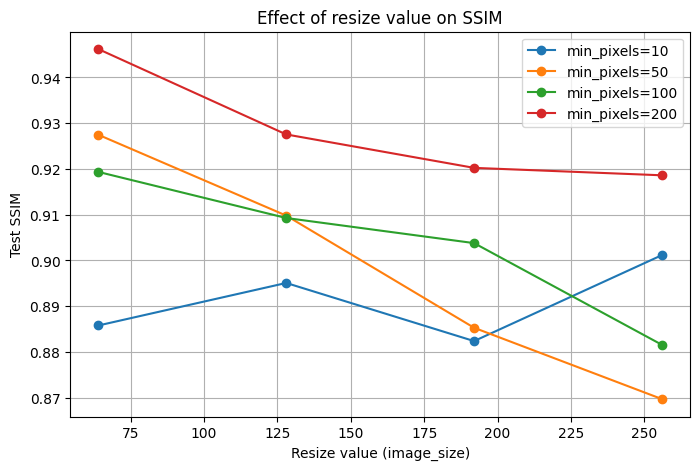

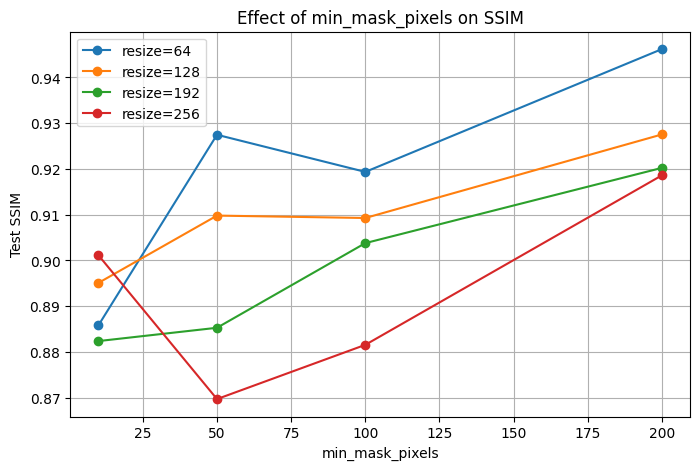

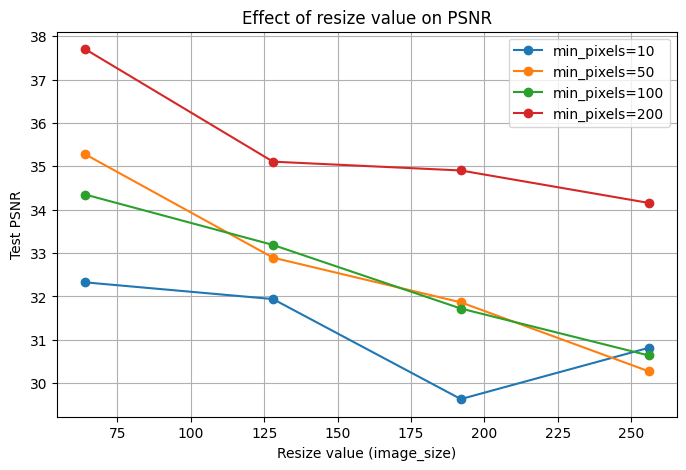

In [ ]:
#plot SSIM with resize value on x axis
#each line represents a different min_mask_pixels value
plt.figure(figsize=(8, 5))
for min_pixels in min_mask_pixels_values:
    subset = results_df[results_df["min_mask_pixels"] == min_pixels].sort_values("image_size")
    plt.plot(subset["image_size"], subset["test_ssim"], marker="o", label=f"min_pixels={min_pixels}")
plt.xlabel("Resize value (image_size)")
plt.ylabel("Test SSIM")
plt.title("Effect of resize value on SSIM")
plt.legend()
plt.grid(True)
plt.show()

#plot SSIM with min_mask_pixels on x axis
#each line represents a different resize value
plt.figure(figsize=(8, 5))
for size in resize_sizes:
    subset = results_df[results_df["image_size"] == size].sort_values("min_mask_pixels")
    plt.plot(subset["min_mask_pixels"], subset["test_ssim"], marker="o", label=f"resize={size}")
plt.xlabel("min_mask_pixels")
plt.ylabel("Test SSIM")
plt.title("Effect of min_mask_pixels on SSIM")
plt.legend()
plt.grid(True)
plt.show()

#plot PSNR with resize value on x axis
#each line represents a different min_mask_pixels value
plt.figure(figsize=(8, 5))
for min_pixels in min_mask_pixels_values:
    subset = results_df[results_df["min_mask_pixels"] == min_pixels].sort_values("image_size")
    plt.plot(subset["image_size"], subset["test_psnr"], marker="o", label=f"min_pixels={min_pixels}")
plt.xlabel("Resize value (image_size)")
plt.ylabel("Test PSNR")
plt.title("Effect of resize value on PSNR")
plt.legend()
plt.grid(True)
plt.show()

#plot PSNR with min_mask_pixels on x axis
#each line represents a different resize value
plt.figure(figsize=(8, 5))
for size in resize_sizes:
    subset = results_df[results_df["image_size"] == size].sort_values("min_mask_pixels")
    plt.plot(subset["min_mask_pixels"], subset["test_psnr"], marker="o", label=f"resize={size}")
plt.xlabel("min_mask_pixels")
plt.ylabel("Test PSNR")
plt.title("Effect of min_mask_pixels on PSNR")
plt.legend()
plt.grid(True)
plt.show()


## 13. Comparison visualization across experiment instances


In [ ]:
def get_sample_tuple_from_subset(dataset, index): #gets raw sample tuple from a dataset or nested random_split subset
    if isinstance(dataset, torch.utils.data.Subset): #checks if dataset is a Subset created by random_split
        return get_sample_tuple_from_subset(dataset.dataset, dataset.indices[index]) #recursively maps subset index to original dataset index
    return dataset.samples[index] #returns (pet_path, mask_path, z) from the original AutoPETSliceDataset


def preprocess_raw_sample_for_experiment(sample_tuple, image_size, resize_images=True): #prepares the same raw sample using one experiment's preprocessing
    pet_path, mask_path, z = sample_tuple #gets PET path, mask path and slice index

    pet_vol = nib.load(pet_path).get_fdata() #loads full 3D PET volume
    mask_vol = nib.load(mask_path).get_fdata() #loads full 3D mask volume

    pet = pet_vol[:, :, z].astype(np.float32) #extracts one 2D PET slice
    mask = (mask_vol[:, :, z] > 0).astype(np.float32) #extracts and binarizes matching mask slice

    pet = (pet - pet.min()) / (pet.max() - pet.min() + 1e-8) #normalizes PET to [0,1]

    pet = torch.tensor(pet).unsqueeze(0) #converts PET to tensor and adds channel dimension
    mask = torch.tensor(mask).unsqueeze(0) #converts mask to tensor and adds channel dimension

    if resize_images: #applies the resize used by the selected experiment
        resize_pet = transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.BILINEAR) #PET resize uses bilinear interpolation
        resize_mask = transforms.Resize((image_size, image_size), interpolation=transforms.InterpolationMode.NEAREST) #mask resize uses nearest-neighbor interpolation
        pet = resize_pet(pet) #resizes PET to the experiment size
        mask = resize_mask(mask) #resizes mask to the experiment size

    pet = pet * 2.0 - 1.0 #converts PET from [0,1] to [-1,1] to match Tanh output
    return mask, pet #returns mask condition and PET target


@torch.no_grad()
def predict_for_raw_sample(result, sample_tuple, device): #generates PET prediction for one raw sample using one saved experiment model
    generator = result["generator"] #gets loaded best generator for this experiment
    generator.eval() #sets generator to evaluation mode

    image_size = result["params"]["image_size"] #gets image_size used by this experiment
    resize_images = result["params"]["resize_images"] #gets whether resizing was used by this experiment

    mask, real_pet = preprocess_raw_sample_for_experiment(sample_tuple, image_size, resize_images=resize_images) #preprocesses same raw sample for this experiment

    mask_input = mask.unsqueeze(0).to(device) #adds batch dimension and moves mask to device
    fake_pet = generator(mask_input).cpu()[0] #generates fake PET and removes batch dimension

    real_pet = (real_pet + 1.0) / 2.0 #converts real PET back to [0,1] for visualization
    fake_pet = (fake_pet + 1.0) / 2.0 #converts fake PET back to [0,1] for visualization

    return real_pet[0].cpu(), fake_pet[0].cpu() #returns 2D real PET and generated PET


def visualize_predictions_across_experiments(results, split="val", n_samples=2, device=device): #visualizes ground truth and predictions from all experiment instances
    reference_result = results[0] #uses first experiment only to choose raw validation/test samples

    if split == "val":
        reference_dataset = reference_result["val_dataset"] #uses validation split
        split_title = "validation"
    elif split == "test":
        reference_dataset = reference_result["test_dataset"] #uses test split
        split_title = "test"
    else:
        raise ValueError("split must be 'val' or 'test'") #prevents using unsupported split names

    n_experiments = len(results) #number of trained experiment instances
    n_rows = min(n_samples, len(reference_dataset)) #number of samples to visualize

    plt.figure(figsize=(3 * (n_experiments + 1), 3 * n_rows)) #creates one column for ground truth and one column per experiment

    for row in range(n_rows): #loops through selected samples
        sample_tuple = get_sample_tuple_from_subset(reference_dataset, row) #gets the raw sample tuple so all experiments use the same original slice

        first_real_pet, _ = predict_for_raw_sample(results[0], sample_tuple, device) #gets ground truth processed with first experiment setting

        plt.subplot(n_rows, n_experiments + 1, row * (n_experiments + 1) + 1)
        plt.imshow(first_real_pet, cmap="gray")
        plt.title("Ground truth")
        plt.axis("off")

        for col, result in enumerate(results): #loops through all experiment instances
            _, fake_pet = predict_for_raw_sample(result, sample_tuple, device) #generates prediction for the same raw sample
            size = result["params"]["image_size"] #gets resize value
            min_pixels = result["params"]["min_mask_pixels"] #gets min_mask_pixels value

            plt.subplot(n_rows, n_experiments + 1, row * (n_experiments + 1) + col + 2)
            plt.imshow(fake_pet, cmap="gray")
            plt.title(f"pred {col+1}\nresize={size}\nmin={min_pixels}")
            plt.axis("off")

    plt.suptitle(f"Ground truth and predictions on {split_title} samples")
    plt.tight_layout()
    plt.show()


In [ ]:
#visualize comparison on validation samples
#columns are ground truth followed by predictions from each experiment instance
visualize_predictions_across_experiments(all_results, split="val", n_samples=2, device=device)

#visualize comparison on test samples
#columns are ground truth followed by predictions from each experiment instance
visualize_predictions_across_experiments(all_results, split="test", n_samples=2, device=device)
